<div dir="rtl">

# مشروع صغير: تحليل طلبات مطعم بمساعدة الذكاء الاصطناعي
**السؤال الرئيسي:** أين تربح إدارة المطعم، ومتى يزدحم، وما الذي يُغضب العملاء؟

**البيانات:** `restaurant_orders.csv` (طلبات 3 فروع، يناير إلى يونيو 2025). اقرأ `data_dictionary_restaurant.md` أولًا.

**المهارات المستخدمة في Cursor:** `/data-quality-report` ← `/kpi-summary` ← `/clear-charts` ← `/insight-report`

**طريقة العمل:** لكل سؤال: اطلب من Agent الكود (أو استدعِ المهارة)، اقرأ الكود قبل قبوله، شغّله، ثم قارن بنقطة التحقق.

</div>

In [1]:
import sys
import numpy as np
import pandas as pd

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: d:\AI\‏‏session2\.venv\Scripts\python.exe
NumPy: 2.5.4
Pandas: 3.1.0


In [3]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("restaurant_orders.csv")
print(df.shape)   # نقطة تحقق: (1515, 12)
df.head()

(1515, 12)


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 1: فحص الجودة والتنظيف
في Agent: `/data-quality-report افحص restaurant_orders.csv` ثم: «نظّف البيانات حسب التقرير واحفظها في clean».

**نقطة تحقق:** 15 صفًا مكررًا، و6 كتابات مختلفة لأسماء الفروع، و136 تقييمًا مفقودًا. بعد التنظيف: **1500 صف** و3 فروع فقط.

</div>

In [5]:
clean = df.drop_duplicates().copy()
clean["branch"] = clean["branch"].str.strip().str.title()
clean["order_date"] = pd.to_datetime(clean["order_date"], errors="raise")

print(f"الصفوف بعد إزالة التكرار: {len(clean)}")
print(f"الفروع بعد التوحيد: {clean['branch'].nunique()} - {sorted(clean['branch'].unique())}")
print(f"التقييمات المفقودة (تُترك دون تعويض): {clean['rating'].isna().sum()}")
print(f"أزمنة التوصيل المفقودة (غير منطبقة لغير التوصيل): {clean['delivery_minutes'].isna().sum()}")
clean.head()


الصفوف بعد إزالة التكرار: 1500
الفروع بعد التوحيد: 3 - ['Downtown', 'Mall', 'University']
التقييمات المفقودة (تُترك دون تعويض): 132
أزمنة التوصيل المفقودة (غير منطبقة لغير التوصيل): 1126


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 2: مؤشرات الأداء (س1)
**س1:** ما إجمالي الإيرادات وعدد الطلبات ومتوسط قيمة الطلب ومتوسط التقييم؟ وما هي لكل فرع؟

في Agent: `/kpi-summary احسب المؤشرات العامة ثم قارن الفروع`

</div>

In [6]:
revenue = clean["total"].sum()
order_count = len(clean)
average_order_value = revenue / order_count
average_rating = clean["rating"].mean()

overall_kpis = pd.DataFrame({
    "المؤشر": ["إجمالي الإيرادات", "عدد الطلبات", "متوسط قيمة الطلب", "متوسط التقييم"],
    "القيمة": [revenue, order_count, average_order_value, average_rating],
})
display(overall_kpis.round(2))

branch_kpis = (
    clean.groupby("branch").agg(
        الإيرادات=("total", "sum"),
        عدد_الطلبات=("total", "size"),
        متوسط_قيمة_الطلب=("total", "mean"),
        متوسط_التقييم=("rating", "mean"),
    )
    .sort_values("الإيرادات", ascending=False)
)
branch_kpis["النسبة من الإجمالي %"] = branch_kpis["الإيرادات"] / revenue * 100
display(branch_kpis.round(2))

assert abs(branch_kpis["الإيرادات"].sum() - revenue) < 1e-9
print("التحقق: مجموع إيرادات الفروع يساوي الإجمالي العام.")
highest = branch_kpis["الإيرادات"].idxmax()
lowest = branch_kpis["الإيرادات"].idxmin()
difference = branch_kpis.loc[highest, "الإيرادات"] - branch_kpis.loc[lowest, "الإيرادات"]
print(f"أعلى مجموعة: {highest} بإيرادات {branch_kpis.loc[highest, 'الإيرادات']:.2f}.")
print(f"أقل مجموعة: {lowest} بإيرادات {branch_kpis.loc[lowest, 'الإيرادات']:.2f}.")
print(f"الفرق بينهما: {difference:.2f}.")


,المؤشر,القيمة
0,إجمالي الإيرادات,18751.00
1,عدد الطلبات,1500.00
2,متوسط قيمة الطلب,12.50
3,متوسط التقييم,4.07


,الإيرادات,عدد_الطلبات,متوسط_قيمة_الطلب,متوسط_التقييم,النسبة من الإجمالي %
branch,,,,,
Mall,7933.0,590,13.45,4.12,42.31
Downtown,6678.0,466,14.33,4.01,35.61
University,4140.0,444,9.32,4.04,22.08


التحقق: مجموع إيرادات الفروع يساوي الإجمالي العام.
أعلى مجموعة: Mall بإيرادات 7933.00.
أقل مجموعة: University بإيرادات 4140.00.
الفرق بينهما: 3793.00.


<div dir="rtl">

## الخطوة 3: الذروة والقنوات والأصناف (س2، س3، س4)
- **س2:** ما ساعات الذروة؟ وأي أيام الأسبوع أكثر ازدحامًا؟
- **س3:** ما حصة كل قناة (صالة، سفري، توصيل) من الإيرادات؟
- **س4:** ما أعلى 5 أصناف من حيث الإيرادات؟

ارسم رسمين على الأقل باستخدام `/clear-charts`.

</div>

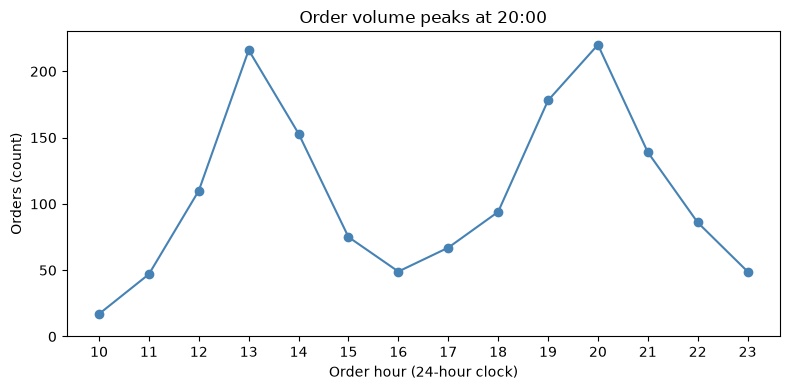

Orders by hour:
order_hour
10     17
11     47
12    110
13    216
14    153
15     75
16     49
17     67
18     94
19    178
20    220
21    139
22     86
23     49


In [7]:
hourly_orders = (
    clean.groupby("order_hour").size()
    .reindex(range(int(clean["order_hour"].min()), int(clean["order_hour"].max()) + 1), fill_value=0)
)
peak_hour = int(hourly_orders.idxmax())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hourly_orders.index, hourly_orders.values, marker="o", color="steelblue")
ax.set(title=f"Order volume peaks at {peak_hour}:00", xlabel="Order hour (24-hour clock)", ylabel="Orders (count)")
ax.set_ylim(bottom=0)
ax.set_xticks(hourly_orders.index)
fig.tight_layout()
plt.show()
print("Orders by hour:")
print(hourly_orders.rename("orders").to_string())


C:\Users\hp\AppData\Local\Temp\ipykernel_26080\2851321813.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  clean["order_date"].dt.dayofweek.map(dict(enumerate(weekday_names)))


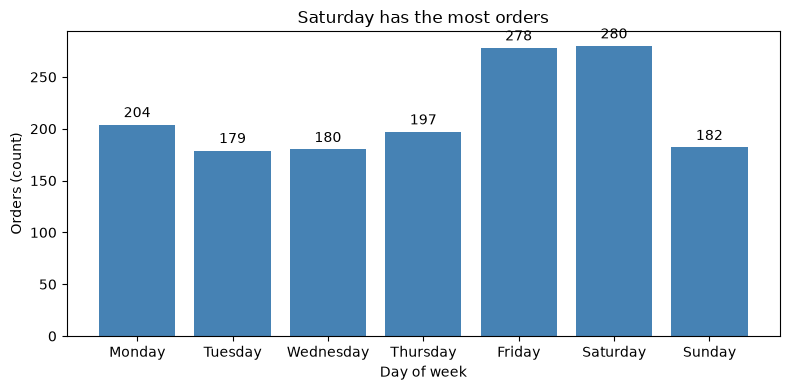

Orders by weekday:
order_date
Monday       204
Tuesday      179
Wednesday    180
Thursday     197
Friday       278
Saturday     280
Sunday       182


In [8]:
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_orders = (
    clean["order_date"].dt.dayofweek.map(dict(enumerate(weekday_names)))
    .value_counts()
    .reindex(weekday_names, fill_value=0)
)
busiest_day = weekday_orders.idxmax()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(weekday_orders.index, weekday_orders.values, color="steelblue")
ax.set(title=f"{busiest_day} has the most orders", xlabel="Day of week", ylabel="Orders (count)")
ax.set_ylim(bottom=0)
ax.bar_label(bars, fmt="%.0f", padding=3)
fig.tight_layout()
plt.show()
print("Orders by weekday:")
print(weekday_orders.rename("orders").to_string())


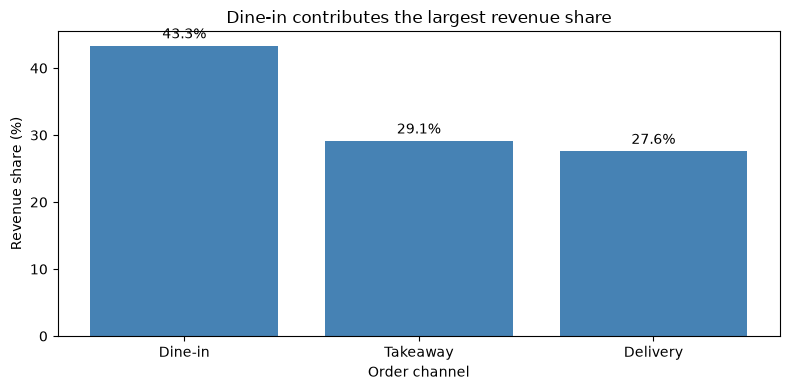

Revenue share by channel:
channel
Dine-in     43.32
Takeaway    29.11
Delivery    27.57


In [9]:
channel_revenue = clean.groupby("channel")["total"].sum().sort_values(ascending=False)
channel_share = channel_revenue / channel_revenue.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(channel_share.index, channel_share.values, color="steelblue")
ax.set(title=f"{channel_share.idxmax()} contributes the largest revenue share", xlabel="Order channel", ylabel="Revenue share (%)")
ax.set_ylim(bottom=0)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
fig.tight_layout()
plt.show()
print("Revenue share by channel:")
print(channel_share.rename("revenue_share_percent").round(2).to_string())


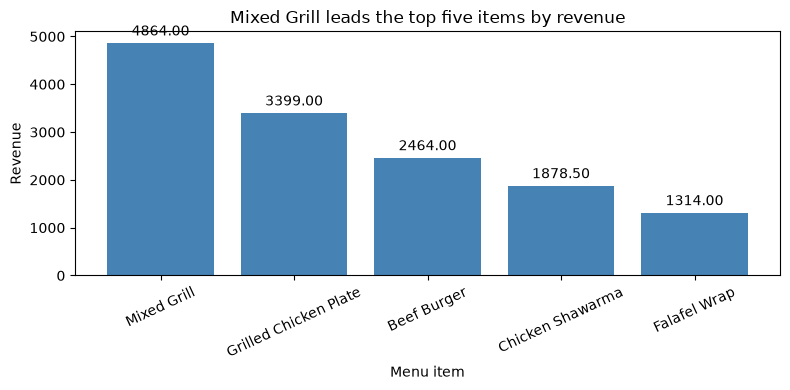

Top five items by revenue:
item
Mixed Grill              4864.0
Grilled Chicken Plate    3399.0
Beef Burger              2464.0
Chicken Shawarma         1878.5
Falafel Wrap             1314.0


In [10]:
top_items_revenue = clean.groupby("item")["total"].sum().nlargest(5)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(top_items_revenue.index, top_items_revenue.values, color="steelblue")
ax.set(title=f"{top_items_revenue.idxmax()} leads the top five items by revenue", xlabel="Menu item", ylabel="Revenue")
ax.set_ylim(bottom=0)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.tick_params(axis="x", labelrotation=25)
fig.tight_layout()
plt.show()
print("Top five items by revenue:")
print(top_items_revenue.rename("revenue").round(2).to_string())


<div dir="rtl">

## الخطوة 4: رضا العملاء (س5)
**س5:** هل يرتبط وقت التوصيل بتقييم العميل؟
قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة.

> هذه مقارنة بين متوسطات، لا تحتاج أي نموذج تعلم آلي. لكنها لا تثبت السبب وحدها.

</div>

In [11]:
# س5: طلبات التوصيل فقط، مقسمة إلى ثلاث فئات زمن (الدقائق أعداد صحيحة)
# الحدود: أقل من 30 | من 30 إلى 45 شاملًا | أكثر من 45
# التقييمات المفقودة تُستبعد من المتوسط فقط، ولا نحذف الصفوف

delivery = clean.loc[clean["channel"] == "Delivery"].copy()
delivery["delivery_band"] = pd.cut(
    delivery["delivery_minutes"],
    bins=[-1, 29, 45, 10**9],
    labels=["< 30 min", "30-45 min", "> 45 min"],
    right=True,
)

band_summary = (
    delivery.groupby("delivery_band", observed=True).agg(
        عدد_الطلبات=("order_id", "size"),
        عدد_التقييمات=("rating", "count"),
        متوسط_التقييم=("rating", "mean"),
    )
)
display(band_summary.round(2))

print(f"طلبات التوصيل: {len(delivery)}")
print(f"تقييمات مفقودة (لم تدخل في المتوسط): {delivery['rating'].isna().sum()}")
print(f"مجموع عدد الطلبات على الفئات: {int(band_summary['عدد_الطلبات'].sum())}")



,عدد_الطلبات,عدد_التقييمات,متوسط_التقييم
delivery_band,,,
< 30 min,69,61,4.11
30-45 min,200,185,3.59
> 45 min,105,94,2.47


طلبات التوصيل: 374
تقييمات مفقودة (لم تدخل في المتوسط): 34
مجموع عدد الطلبات على الفئات: 374


<div dir="rtl">

### ناتج س5 والسبب

المصدر: 374 طلب توصيل بعد التنظيف، وجميعها لها قيمة `delivery_minutes`. التقييمات المفقودة 34، واستُبعدت من المتوسط فقط.

| فئة زمن التوصيل | عدد الطلبات | عدد التقييمات المستخدمة | متوسط التقييم |
| --- | ---: | ---: | ---: |
| أقل من 30 دقيقة | 69 | 61 | 4.11 |
| من 30 إلى 45 دقيقة | 200 | 185 | 3.59 |
| أكثر من 45 دقيقة | 105 | 94 | 2.47 |

**الناتج:** نعم، يظهر ارتباط وصفي: كلما طال زمن التوصيل انخفض متوسط التقييم، وأضعف رضا عند التوصيل الذي يتجاوز 45 دقيقة.

**السبب / حد التفسير:** هذه مقارنة بين متوسطات ثلاث فئات وليست نموذج تعلم آلي. الارتباط وحده لا يثبت أن زمن التوصيل هو سبب التقييم؛ قد تشترك عوامل أخرى (ازدحام الفرع، ساعة الذروة، دقة الطلب) مع الزمن والتقييم معًا.

</div>

<div dir="rtl">

## الخطوة 5: الرؤى والتوصيات (س6)
في Agent: `/insight-report اكتب الرؤى والتوصيات من نتائج هذا الدفتر واحفظها في insights.md`

التقرير محفوظ في `insights.md`.

ثم راجع: هل كل رقم في التقرير موجود فعلًا في مخرجات الدفتر؟ سجّل أي خطأ في سجل التحقق أدناه.

## سجل التحقق
| ماذا قال الذكاء الاصطناعي | كيف تحققت | النتيجة |
| --- | --- | --- |
| الشكل الخام (1515، 12) و15 صفًا مكررًا و1500 صف بعد التنظيف و3 فروع | عدّ الصفوف والتكرارات في CSV، ثم توحيد أسماء الفروع | **مطابق:** 1515 صفًا خامًا؛ حُذف 15 تكرارًا فأصبح العدد 1500، وتوحّدت أسماء الفروع إلى Downtown وMall وUniversity. |
| 136 تقييمًا مفقودًا | عدّ القيم الفارغة في `rating` قبل حذف التكرارات وبعده | **مطابق مع توضيح:** 136 قيمة مفقودة في الملف الخام، و132 بعد حذف التكرارات؛ الرقم 132 هو الصحيح للبيانات المنظّفة. |
| إجمالي الإيرادات 18751.00 و1500 طلبًا ومتوسط طلب 12.50 ومتوسط تقييم 4.07 | إعادة حساب المؤشرات من الصفوف المنظّفة في CSV | **مطابق:** الإيرادات 18751.00؛ العدد 1500؛ متوسط قيمة الصف 12.50؛ ومتوسط التقييم المتاح 4.07. لم تُحفظ مخرجات الخلية في الدفتر، لذا جرى التحقق مباشرة من CSV. |
| المول 7933.00 (42.31٪) ووسط المدينة 6678.00 (35.61٪) والجامعة 4140.00 (22.08٪) والفرق 3793.00 | تجميع `total` حسب الفرع بعد توحيد الأسماء | **مطابق:** إيرادات الفروع 7933.00 و6678.00 و4140.00؛ مجموعها 18751.00، والفرق بين الأعلى والأقل 3793.00. النسب 42.31٪ و35.61٪ و22.08٪. |
| متوسط قيمة الطلب: جامعة 9.32، مول 13.45، وسط المدينة 14.33؛ التقييمات 4.12 / 4.01 / 4.04 | حساب المتوسطات لكل فرع مع استبعاد التقييمات الفارغة فقط | **مطابق:** الجامعة 9.32 وتقييمها 4.04؛ المول 13.45 وتقييمه 4.12؛ وسط المدينة 14.33 وتقييمها 4.01. |
| الذروة الساعة 20 بـ 220 طلبًا، وساعة 13 بـ 216 طلبًا | عدّ الطلبات حسب `order_hour` | **مطابق:** الساعة 20 هي الأعلى (220)، تليها الساعة 13 (216). |
| السبت 280 طلبًا والجمعة 278 والثلاثاء 179 | اشتقاق يوم الأسبوع من `order_date` ثم عدّ الطلبات | **مطابق:** السبت 280، الجمعة 278، والثلاثاء هو الأقل بـ179 طلبًا. |
| حصة الإيرادات: صالة 43.32٪، سفري 29.11٪، توصيل 27.57٪ | جمع `total` حسب القناة وقسمة كل مجموع على الإيراد الكلي | **مطابق:** الصالة 8122.00 (43.32٪)، السفري 5459.00 (29.11٪)، والتوصيل 5170.00 (27.57٪)؛ مجموع الحصص 100٪ بعد التقريب. |
| أعلى صنف Mixed Grill بإيراد 4864.00 ثم Grilled Chicken Plate 3399.00 | جمع `total` حسب الصنف وترتيب النتائج تنازليًا | **مطابق:** Mixed Grill أولًا (4864.00)، ثم Grilled Chicken Plate (3399.00). |
| التوصيل 374 طلبًا و34 تقييمًا مفقودًا؛ المتوسطات 4.11 و3.59 و2.47 للفئات &lt;30 و30–45 و&gt;45 (69 / 200 / 105 طلبًا) | تصفية طلبات التوصيل وتجميعها حسب حدود الزمن المحددة، مع تجاهل التقييمات الفارغة عند المتوسط | **مطابق:** 374 طلبًا و34 تقييمًا مفقودًا؛ الفئات تضم 69 و200 و105 طلبات، وعدد التقييمات المحتسبة 61 و185 و94، ومتوسطاتها 4.11 و3.59 و2.47. الاتجاه وصفي ولا يثبت السببية. |

</div>